# Supplementary — paired Delay P75

Original analysis and visualization from `insula-functional/vizpub/fig3.ipynb`,
cell `fig3-paired-plot`, which generated `img/fig3/fig3_paired_delay_p75.svg`.
This independent notebook uses the current frozen three-phase NMF labels,
the same saved per-electrode contrasts and the exact original plotting code.
It reproduces the already-approved current Figure 3 paired tables/statistics.

- Picture Naming: Repeat–Passive; color uses uncorrected p<0.05 and Repeat>Passive.
- Lexical Delay: Decision–Repeat; color uses the original FDR and Decision>Repeat.
- Each line pairs the same electrode across the two conditions.
- P75 is calculated within each trial's original Delay window (0–0.5 s),
  then averaged over trials. It is not the top 75% of electrodes or trials.
- Per-cluster inference is the original one-sided paired Wilcoxon,
  without a newly introduced group multiple-testing correction.

The original upstream trial reduction/permutation/FDR implementation remains
in `src/univariate/contrasts_mean.py`; this notebook reuses those saved tests,
then executes the original pairing, group inference and plotting. It does not
redefine the original FDR family or change the main sampling/NMF analysis.


In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')
from pathlib import Path
import os,sys,json,hashlib
ROOT=Path('../..').resolve()
sys.path.insert(0,str(ROOT))
os.environ['INSULA_HGA_INPUT_ROOT']='/hpc/group/coganlab/nanlinshi/insula-functional/results/hga'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from src.nmf.waveform_analysis import FUNCTION_COLORS,CLUSTER_LABELS
from src.paths import save_svg,nmf_assignments_path
from src.univariate.contrasts_mean import PHASE_WINDOWS,WINDOW_P75,window_reduce
for path in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(path))
plt.rcParams['svg.fonttype']='none'
plt.rcParams['font.family']='sans-serif'
plt.rcParams['font.sans-serif']=['Arial']
cm=1/2.54;fontsize=7
EXCLUDE_SUBJECTS={'D0121'}
IMG_DIR=ROOT/'img/supplementary/paired_delay_p75'
DATA_DIR=ROOT/'results/supplementary/paired_delay_p75'
IMG_DIR.mkdir(parents=True,exist_ok=True);DATA_DIR.mkdir(parents=True,exist_ok=True)
print('Original per-trial statistic:',WINDOW_P75,'percentile; Delay window:',PHASE_WINDOWS['Delay'])
print('Frozen assignments:',nmf_assignments_path())


Original per-trial statistic: 75.0 percentile; Delay window: (0.0, 0.5)
Frozen assignments: /cwork/ns458/insula-paper/results/nmf/channel_assignments.csv


## Original loading, pairing, inference and plotting helpers


In [2]:
from matplotlib.colors import to_hex, to_rgb
from scipy.stats import gaussian_kde, wilcoxon

from src.paths import RESULTS_ROOT
from src.univariate.viz_cluster_direction import load_nmf_assignments
from src.univariate.viz_mean import (
    FALLBACK_MEAN_RESULTS,
    attach_metadata,
    filter_insula_electrodes,
    filter_qc,
    load_coord_metadata,
    load_mean_contrasts,
)


def _mix_hex(color, other, amount):
    a = np.asarray(to_rgb(color))
    b = np.asarray(to_rgb(other))
    return to_hex(a * (1.0 - amount) + b * amount)


def _condition_color(cluster, condition):
    base = FUNCTION_COLORS[cluster]
    if condition == "Passive":
        return "black"
    if condition == "Repeat":
        return base
    if condition == "Decision":
        return _mix_hex(base, "black", 0.28)
    raise ValueError(condition)


def _p_stars(p):
    if not np.isfinite(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


NS_COLOR = "0.62"
LINE_COLOR = "0.82"
X0, X1 = 0.0, 1.0
VIOLIN_W = 0.22
CLUSTER_DISPLAY = ["sensory", "sustain", "motor"]


def _load_paired(contrast, tasks, *, color_fdr):
    mean_df = load_mean_contrasts(
        RESULTS_ROOT,
        tasks=tasks,
        phase="Delay",
        contrast_desc=contrast,
    )
    coords = load_coord_metadata(FALLBACK_MEAN_RESULTS, tasks=tasks)
    paired = attach_metadata(mean_df, coords)
    paired = filter_qc(paired)
    paired = filter_insula_electrodes(paired)
    paired = paired.loc[
        (paired["contrast"] == contrast)
        & (paired["phase"].str.lower() == "delay")
    ].copy()
    if "subject" in paired.columns:
        paired = paired.loc[~paired["subject"].isin(EXCLUDE_SUBJECTS)].copy()
    assign = load_nmf_assignments(k=3)
    paired = paired.merge(
        assign[["channel", "functional_cluster"]],
        on="channel",
        how="inner",
    )
    paired = paired.drop_duplicates(subset=["channel"], keep="first")
    paired = paired.loc[paired[["mean_a", "mean_b"]].notna().all(axis=1)].copy()
    paired["significant"] = paired["significant"].astype(bool)
    if color_fdr:
        paired["sig_up"] = paired["significant"] & (paired["mean_a"] > paired["mean_b"])
    else:
        paired["sig_up"] = (paired["p_value"] < 0.05) & (paired["mean_a"] > paired["mean_b"])
    return paired.loc[paired["functional_cluster"].isin(CLUSTER_DISPLAY)].copy()


def _half_violin(ax, values, x, *, side, color):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    if len(v) < 3:
        return
    y = np.linspace(np.percentile(v, 2), np.percentile(v, 98), 200)
    dens = gaussian_kde(v)(y)
    dens = dens / dens.max() * VIOLIN_W
    xs = x - dens if side == "left" else x + dens
    ax.fill_betweenx(y, np.full_like(xs, x), xs, color=color, alpha=0.18, lw=0, zorder=0)
    ax.plot(xs, y, color=color, lw=0.7, zorder=1)


def _draw_cluster(
    ax, sub, cluster, *, xticklabels, ybar, span, ylim, left, right, show_title=True
):
    left_color = _condition_color(cluster, xticklabels[0])
    right_color = _condition_color(cluster, xticklabels[1])
    _half_violin(ax, sub[left], X0, side="left", color=left_color)
    _half_violin(ax, sub[right], X1, side="right", color=right_color)
    ns = sub.loc[~sub["sig_up"]]
    sig = sub.loc[sub["sig_up"]]
    for _, row in ns.iterrows():
        ax.plot(
            [X0, X1],
            [row[left], row[right]],
            color=LINE_COLOR,
            lw=0.45,
            zorder=1,
            solid_capstyle="round",
        )
    for _, row in sig.iterrows():
        ax.plot(
            [X0, X1],
            [row[left], row[right]],
            color=left_color,
            lw=0.7,
            zorder=2,
            solid_capstyle="round",
        )
    if len(ns):
        ax.scatter(
            np.full(len(ns), X0),
            ns[left],
            s=10,
            c=NS_COLOR,
            zorder=3,
            linewidths=0,
            clip_on=False,
        )
        ax.scatter(
            np.full(len(ns), X1),
            ns[right],
            s=10,
            c=NS_COLOR,
            zorder=3,
            linewidths=0,
            clip_on=False,
        )
    if len(sig):
        ax.scatter(
            np.full(len(sig), X0),
            sig[left],
            s=14,
            c=left_color,
            zorder=4,
            linewidths=0,
            clip_on=False,
        )
        ax.scatter(
            np.full(len(sig), X1),
            sig[right],
            s=14,
            c=right_color,
            zorder=4,
            linewidths=0,
            clip_on=False,
        )
    if len(sub) >= 8:
        _, p_c = wilcoxon(
            sub["mean_a"].to_numpy(float),
            sub["mean_b"].to_numpy(float),
            alternative="greater",
            zero_method="wilcox",
        )
        p_txt = f"p = {p_c:.3g}"
    else:
        p_c = np.nan
        p_txt = "n < 8"
    ax.plot([X0, X1], [ybar, ybar], color="0.2", lw=0.7, clip_on=False)
    ax.plot([X0, X0], [ybar - 0.03 * span, ybar], color="0.2", lw=0.7, clip_on=False)
    ax.plot([X1, X1], [ybar - 0.03 * span, ybar], color="0.2", lw=0.7, clip_on=False)
    ax.text(
        0.5,
        ybar + 0.02 * span,
        p_txt,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        color="0.2",
        clip_on=False,
        fontstyle="italic",
        fontfamily="Arial",
    )
    ax.text(
        0.5,
        ybar + 0.14 * span,
        f"n={len(sub)}",
        ha="center",
        va="bottom",
        fontsize=fontsize,
        color="0.2",
        clip_on=False,
        fontfamily="Arial",
    )
    stars = _p_stars(p_c)
    if stars:
        ax.text(
            0.5,
            ybar - 0.015 * span,
            stars,
            ha="center",
            va="top",
            fontsize=fontsize + 1,
            color="0.2",
            clip_on=False,
            fontfamily="Arial",
        )
    ax.set_xlim(-0.55, 1.55)
    ax.set_ylim(*ylim)
    ax.set_xticks([X0, X1], xticklabels)
    if show_title:
        ax.set_title(CLUSTER_LABELS[cluster], fontsize=fontsize)
    ax.tick_params(labelsize=fontsize, width=0.75, length=2, which="both")
    plt.setp(ax.spines.values(), linewidth=0.75)
    sns.despine(ax=ax, offset=1, trim=True)
    return p_c




## Original two-by-three paired plot


2026-10-18 20:55:23,190 INFO: Loaded NMF k=3 assignments from /cwork/ns458/insula-paper/results/nmf/channel_assignments.csv (231 channels)


2026-10-18 20:55:31,667 INFO: Loaded NMF k=3 assignments from /cwork/ns458/insula-paper/results/nmf/channel_assignments.csv (231 channels)


Repeat>Passive Delay P75: 94 (unc p<0.05=14)
functional_cluster
sensory    2
sustain    8
motor      4
Decision>Repeat Delay P75: 137 (FDR=24)
functional_cluster
sensory     4
sustain    15
motor       5


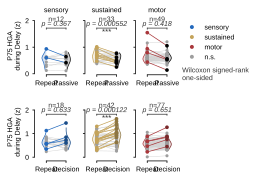

Wrote /cwork/ns458/insula-paper/img/supplementary/paired_delay_p75/supp_paired_delay_p75.svg
  Repeat>Passive sensory: n=12, sig=2, p=0.3667
  Repeat>Passive sustain: n=33, sig=8, p=0.0005518
  Repeat>Passive motor: n=49, sig=4, p=0.418
  Decision>Repeat sensory: n=18, sig=4, p=0.6331
  Decision>Repeat sustain: n=42, sig=15, p=0.000122
  Decision>Repeat motor: n=77, sig=5, p=0.6511


In [3]:
rvp = _load_paired("RepeatVsPassiveP75", ("PictureNaming",), color_fdr=False)
dvr = _load_paired("DecisionVsRepeatP75", ("LexicalDelay",), color_fdr=True)
print(
    f"Repeat>Passive Delay P75: {len(rvp)} "
    f"(unc p<0.05={int(rvp['sig_up'].sum())})"
)
print(
    rvp.loc[rvp["sig_up"]]
    .groupby("functional_cluster")["channel"]
    .nunique()
    .reindex(CLUSTER_DISPLAY)
    .fillna(0)
    .astype(int)
    .to_string()
)
print(
    f"Decision>Repeat Delay P75: {len(dvr)} "
    f"(FDR={int(dvr['sig_up'].sum())})"
)
print(
    dvr.loc[dvr["sig_up"]]
    .groupby("functional_cluster")["channel"]
    .nunique()
    .reindex(CLUSTER_DISPLAY)
    .fillna(0)
    .astype(int)
    .to_string()
)

rows = [
    (rvp, ["Repeat", "Passive"], "P75 HGA\nduring Delay (z)", "mean_a", "mean_b"),
    (dvr, ["Repeat", "Decision"], "P75 HGA\nduring Delay (z)", "mean_b", "mean_a"),
]
fig, axes = plt.subplots(2, 3, figsize=(6.5 * cm, 6.5 * cm), sharey="row")
fig.subplots_adjust(hspace=0.55, wspace=0.22)
cluster_stats = []
for row, (paired, ticks, ylabel, left, right) in enumerate(rows):
    ymin = float(np.nanmin(np.r_[paired["mean_a"], paired["mean_b"]]))
    ymax = float(np.nanmax(np.r_[paired["mean_a"], paired["mean_b"]]))
    span = ymax - ymin if ymax > ymin else 1.0
    ylim = (ymin - 0.08 * span, ymax + 0.38 * span)
    ybar = ymax + 0.12 * span
    for col, cluster in enumerate(CLUSTER_DISPLAY):
        ax = axes[row, col]
        sub = paired.loc[paired["functional_cluster"] == cluster].copy()
        p_c = _draw_cluster(
            ax,
            sub,
            cluster,
            xticklabels=ticks,
            ybar=ybar,
            span=span,
            ylim=ylim,
            left=left,
            right=right,
            show_title=row == 0,
        )
        cluster_stats.append((row, cluster, len(sub), int(sub["sig_up"].sum()), p_c))
    axes[row, 0].set_ylabel(ylabel, fontsize=fontsize)

handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=FUNCTION_COLORS[c],
        markeredgecolor="none",
        markersize=4,
        label=CLUSTER_LABELS[c],
    )
    for c in CLUSTER_DISPLAY
] + [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=NS_COLOR,
        markeredgecolor="none",
        markersize=4,
        label="n.s.",
    )
]
leg = axes[0, -1].legend(
    handles=handles,
    frameon=False,
    fontsize=fontsize,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
)
fig.canvas.draw()
bbox = leg.get_window_extent(fig.canvas.get_renderer()).transformed(
    fig.transFigure.inverted()
)
fig.text(
    bbox.x0,
    bbox.y0 - 0.02,
    "Wilcoxon signed-rank\none-sided",
    ha="left",
    va="top",
    fontsize=fontsize,
    color="0.2",
    fontfamily="Arial",
    linespacing=1.25,
)

out = save_svg(fig, IMG_DIR / "supp_paired_delay_p75")
plt.show()
print("Wrote", out)
for row, cluster, n, n_sig_c, p_c in cluster_stats:
    name = "Repeat>Passive" if row == 0 else "Decision>Repeat"
    p_str = f"{p_c:.4g}" if np.isfinite(p_c) else "NA"
    print(f"  {name} {cluster}: n={n}, sig={n_sig_c}, p={p_str}")

## Complete electrode lists, subject counts and provenance


In [4]:
# Store the complete paired lists and reproduce the already-approved Figure 3 result.
from src.univariate.viz_mean import discover_mean_paths,task_results_dir
def file_sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
assign=pd.read_csv(nmf_assignments_path())
membership=[]
for name,frame,comparison,task in [
    ('rvp',rvp,'RepeatVsPassiveP75','PictureNaming'),
    ('dvr',dvr,'DecisionVsRepeatP75','LexicalDelay')]:
    assert frame.channel.is_unique and set(frame.channel).issubset(set(assign.channel))
    assert frame[['mean_a','mean_b']].notna().all().all()
    reference=pd.read_csv(ROOT/f'results/fig3/available_{name}.csv')
    columns=['channel','functional_cluster','mean_a','mean_b','p_value','significant','sig_up']
    pd.testing.assert_frame_equal(frame[columns].sort_values('channel').reset_index(drop=True),
        reference[columns].sort_values('channel').reset_index(drop=True),check_exact=False,rtol=1e-12,atol=1e-12)
    frame.to_csv(DATA_DIR/f'{comparison}_electrodes.csv',index=False)
    for cluster,group in frame.groupby('functional_cluster'):
        membership.append(dict(task=task,contrast=comparison,cluster=cluster,
            n_subjects=group.subject.nunique(),n_electrodes=group.channel.nunique(),n_highlighted=int(group.sig_up.sum())))
stats=pd.DataFrame(cluster_stats,columns=['contrast_row','functional_cluster','n_electrodes','n_highlighted','wilcoxon_p'])
expected=pd.read_csv(ROOT/'results/fig3/available_paired_statistics.csv').rename(columns={'n_sites':'n_electrodes'})
pd.testing.assert_frame_equal(stats,expected,check_exact=False,rtol=1e-12,atol=1e-12)
stats.to_csv(DATA_DIR/'cluster_statistics.csv',index=False)
pd.DataFrame(membership).to_csv(DATA_DIR/'subject_cluster_counts.csv',index=False)
sources={str(nmf_assignments_path()):file_sha(nmf_assignments_path())}
for task,contrast in [('PictureNaming','RepeatVsPassiveP75'),('LexicalDelay','DecisionVsRepeatP75')]:
    for p in discover_mean_paths(RESULTS_ROOT,task,'Delay',contrast):sources[str(p)]=file_sha(p)
    for p in task_results_dir(FALLBACK_MEAN_RESULTS,task).glob('**/HGA/*coord.csv'):
        sources[str(p)]=file_sha(p)
manifest=dict(completed=True,original_source_notebook='/hpc/group/coganlab/nanlinshi/insula-functional/vizpub/fig3.ipynb',
    original_source_cell='fig3-paired-plot',current_Figure3_membership_values_and_statistics_reproduced=True,
    analysis_unit='electrode; paired within each electrode',trial_summary='75th percentile, then condition mean',
    phase='Delay',original_window_seconds=list(PHASE_WINDOWS['Delay']),
    upstream_original_analysis='src/univariate/contrasts_mean.py',
    upstream_original_analysis_sha256=file_sha(ROOT/'src/univariate/contrasts_mean.py'),
    single_electrode_tests='Reused saved original permutation p and original FDR family; no smaller-family refit',
    RepeatVsPassive_highlight='uncorrected p<0.05 and Repeat>Passive',
    DecisionVsRepeat_highlight='original FDR significance and Decision>Repeat',
    cluster_test='Original paired, one-sided Wilcoxon; n>=8; zero_method=wilcox',
    group_p_values_adjusted=False,plotting='Original fig3-paired-plot; output directory/name only changed',
    n_repeat_passive=len(rvp),n_decision_repeat=len(dvr),
    assignments_sha256=file_sha(nmf_assignments_path()),source_files=sources,
    output=str(IMG_DIR/'supp_paired_delay_p75.svg'),main_figures_and_NMF_rewritten=False)
(DATA_DIR/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
display(pd.DataFrame(membership));display(stats)


,task,contrast,cluster,n_subjects,n_electrodes,n_highlighted
0,PictureNaming,RepeatVsPassiveP75,motor,20,49,4
1,PictureNaming,RepeatVsPassiveP75,sensory,8,12,2
2,PictureNaming,RepeatVsPassiveP75,sustain,17,33,8
3,LexicalDelay,DecisionVsRepeatP75,motor,31,77,5
4,LexicalDelay,DecisionVsRepeatP75,sensory,10,18,4
5,LexicalDelay,DecisionVsRepeatP75,sustain,19,42,15


,contrast_row,functional_cluster,n_electrodes,n_highlighted,wilcoxon_p
0,0,sensory,12,2,0.366699
1,0,sustain,33,8,0.000552
2,0,motor,49,4,0.418000
3,1,sensory,18,4,0.633137
4,1,sustain,42,15,0.000122
5,1,motor,77,5,0.651150
